In [ ]:
2 + 2

4

In [ ]:
3 * 4

12

In [ ]:
120 / 4

30.0

In [ ]:
nome = "Romeu"

In [ ]:
print(nome)

Romeu


In [ ]:
idade = 29
idade

29

In [ ]:
formacao = "Marketing"
curso = "Data Science para Marketing"

In [ ]:
print(f"Olá, {nome}! Notamos que você é formado em {formacao}. Bem vindo(a) ao curso {curso}")

Olá, Romeu! Notamos que você é formado em Marketing. Bem vindo(a) ao curso Data Science para Marketing


# Analisando o arquivo de campanha

In [7]:
import pandas as pd

In [8]:
campanha = pd.read_csv("/content/campanha.csv")

In [9]:
campanha.head()

,Id_campanha,impressoes,cliques,canal,custo,receita,estado,pais
0,1,152431,9462,Email,13258,32309,MG,Brasil
1,1,39688,3218,PPC,16391,16568,BA,Brasil
2,1,104506,4756,Google Ads,6189,19029,AL,Brasil
3,1,80768,3566,Google Ads,5215,0,PI,Brasil
4,1,54932,3645,Google Ads,16767,8825,RJ,Brasil


In [11]:
campanha['canal']

,canal
0,Email
1,PPC
2,Google Ads
3,Google Ads
4,Google Ads
...,...
49995,Social Media
49996,Google Ads
49997,Google Ads
49998,PPC


In [12]:
campanha['canal'].unique()

array(['Email', 'PPC', 'Google Ads', 'Meta Ads', 'Social Media'],
      dtype=object)

In [13]:
campanha['canal'].value_counts()

,count
canal,
Google Ads,25146
Meta Ads,15009
Social Media,4874
PPC,2526
Email,2445


CTR = (cliques/impressoes)*100

In [14]:
campanha['ctr'] = (campanha['cliques']/campanha['impressoes'])*100

In [15]:
campanha.head()

,Id_campanha,impressoes,cliques,canal,custo,receita,estado,pais,ctr
0,1,152431,9462,Email,13258,32309,MG,Brasil,6.207399
1,1,39688,3218,PPC,16391,16568,BA,Brasil,8.108244
2,1,104506,4756,Google Ads,6189,19029,AL,Brasil,4.550935
3,1,80768,3566,Google Ads,5215,0,PI,Brasil,4.415115
4,1,54932,3645,Google Ads,16767,8825,RJ,Brasil,6.635477


<Axes: >

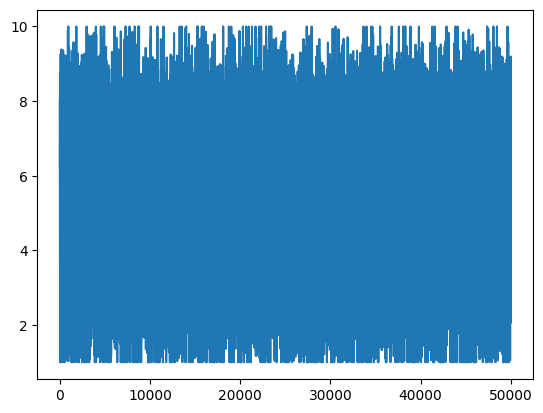

In [16]:
campanha['ctr'].plot()

<Axes: ylabel='Frequency'>

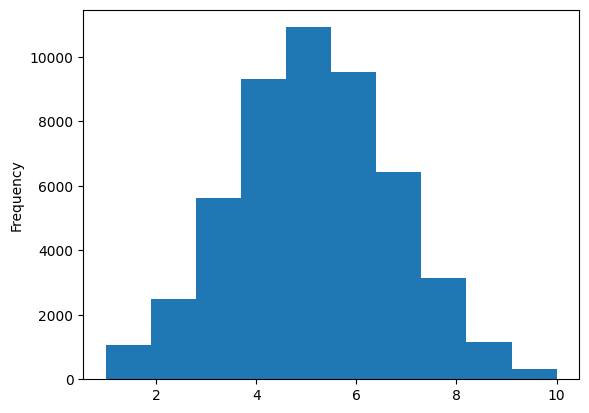

In [17]:
campanha['ctr'].plot(kind='hist')

In [18]:
campanha['ctr'].describe()

,ctr
count,50000.000000
mean,5.148482
std,1.604119
min,0.992663
25%,4.050781
50%,5.132384
75%,6.241502
max,10.000000


In [19]:
campanha['ctr'].median()

5.132384085295483

In [20]:
campanha['ctr'].mean()

np.float64(5.1484815905088634)

In [21]:
import seaborn as sns

<Axes: ylabel='ctr'>

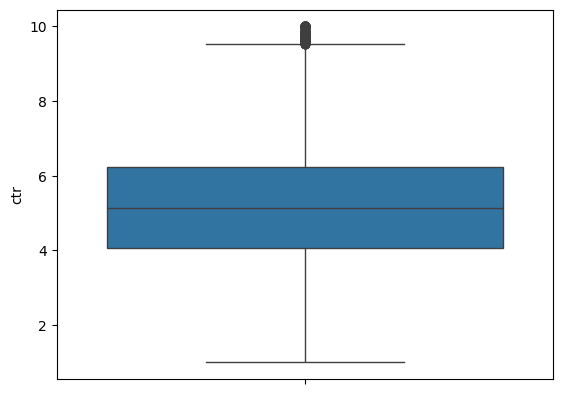

In [22]:
sns.boxplot(campanha['ctr'])

In [23]:
campanha.query('Id_campanha == 1 ')

,Id_campanha,impressoes,cliques,canal,custo,receita,estado,pais,ctr
0,1,152431,9462,Email,13258,32309,MG,Brasil,6.207399
1,1,39688,3218,PPC,16391,16568,BA,Brasil,8.108244
2,1,104506,4756,Google Ads,6189,19029,AL,Brasil,4.550935
3,1,80768,3566,Google Ads,5215,0,PI,Brasil,4.415115
4,1,54932,3645,Google Ads,16767,8825,RJ,Brasil,6.635477
5,1,86472,3266,Google Ads,15870,12483,BA,Brasil,3.776945
6,1,63460,4869,Meta Ads,13769,10849,SP,Brasil,7.672550
7,1,45206,2231,Meta Ads,26270,8583,MA,Brasil,4.935186
8,1,85974,5340,Google Ads,42535,91,PE,Brasil,6.211180
9,1,128497,4717,Meta Ads,10310,19235,MS,Brasil,3.670903


In [24]:
campanha.query('Id_campanha == 1').mean(numeric_only=True)

,0
Id_campanha,1.000000
impressoes,96580.806452
cliques,4902.096774
custo,13863.419355
receita,14000.806452
ctr,5.210398


In [25]:
campanha.query('Id_campanha == 1')['impressoes']

,impressoes
0,152431
1,39688
2,104506
3,80768
4,54932
5,86472
6,63460
7,45206
8,85974
9,128497


In [26]:
campanha.query('Id_campanha == 1')['impressoes'].mean()

np.float64(96580.80645161291)

In [29]:
campanha.groupby('Id_campanha')['impressoes']

In [31]:
medias_por_campanha = campanha.groupby('Id_campanha')['impressoes'].mean()
medias_por_campanha.head()

,impressoes
Id_campanha,
1,96580.806452
2,92372.923077
3,118489.333333
4,96947.681818
5,105508.291667


<Axes: ylabel='Frequency'>

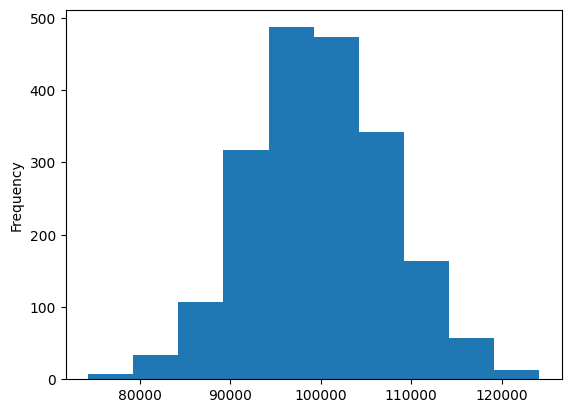

In [32]:
medias_por_campanha.plot(kind='hist')

In [33]:
metricas_por_tipo = campanha.groupby('canal')['ctr'].mean()
metricas_por_tipo

,ctr
canal,
Email,5.109386
Google Ads,5.152163
Meta Ads,5.133841
PPC,5.162208
Social Media,5.187068


<Axes: ylabel='impressoes'>

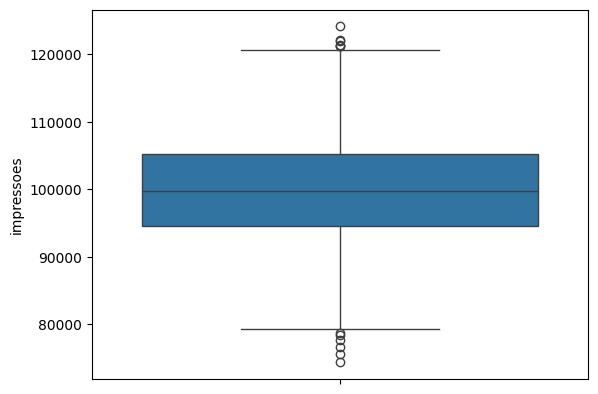

In [34]:
sns.boxplot(medias_por_campanha)

In [35]:
medias_por_campanha.describe()

,impressoes
count,2000.000000
mean,99924.847399
std,7651.690148
min,74315.388889
25%,94601.752717
50%,99731.860577
75%,105173.546176
max,124154.071429


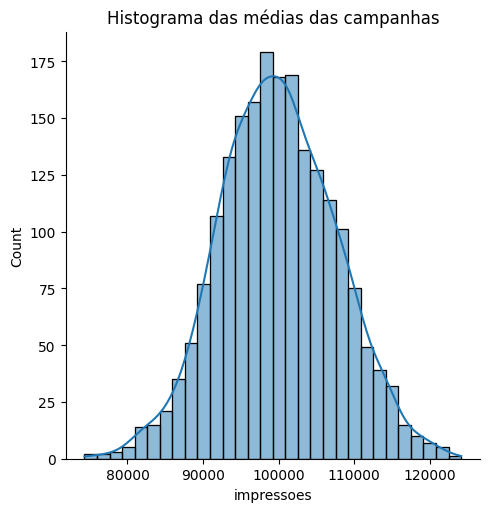

In [42]:
import matplotlib.pyplot as plt



sns.displot(medias_por_campanha, kde = True)

plt.title('Histograma das médias das campanhas')
plt.show()